# Machine Learning Practical · 01
## Regression, risk and approximation

Exercises for **L2-S01–L2-S35**: supervised regression, empirical and population risk,
linear least squares, network representation, and the scope of approximation theorems.

[Exercise guide](README.md) · [Worked laboratory](../ML_01_regression_and_risk.ipynb)

Python 3.11+; install `../requirements-notebook.txt`, then **Restart Kernel and Run All Cells**.
Every starter cell runs as supplied. Cells labelled **EDIT** contain simple baselines;
feedback reports progress without interrupting execution. The supplied outputs show
these baselines, not completed exercise solutions. Work independently of the other notebooks.

**Deliverable:** your edited notebook, a compact comparison table and a paragraph
separating approximation, optimisation and statistical error. Allow 60–90 minutes.

In [1]:
import copy, io, json, platform, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Image

SEED = 4
RUN_MODE = "quick"                 # "quick" or "thorough"
assert RUN_MODE in {"quick", "thorough"}
FACTOR = 1 if RUN_MODE == "quick" else 2
START = time.perf_counter()
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
versions = dict(python=platform.python_version(), numpy=np.__version__,
                matplotlib=matplotlib.__version__, torch=torch.__version__)
print(json.dumps(versions, indent=2))
print(f"CPU / float64 / seed {SEED} / {RUN_MODE} mode")

palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 110, "legend.frameon": False,
    "font.family": "DejaVu Sans",
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "pink", "blue", "navy"]]),
})

def show_figure(fig):
    """Embed a compact static PNG so GitHub can display the result."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def signal(x):
    return np.sin(np.pi*x)

def sample_data(generator, n, sigma=0.05):
    x = np.sort(generator.uniform(0, 1, n))[:, None]
    y = signal(x) + sigma*generator.normal(size=x.shape)
    return x, y

def make_mlp(width=16, depth=2):
    layers = [nn.Linear(1, width), nn.Tanh()]
    for _ in range(depth-1):
        layers += [nn.Linear(width, width), nn.Tanh()]
    return nn.Sequential(*layers, nn.Linear(width, 1))

{
  "python": "3.13.9",
  "numpy": "2.4.2",
  "matplotlib": "3.10.8",
  "torch": "2.10.0"
}
CPU / float64 / seed 4 / quick mode


## A · Empirical risk is a random quantity (L2-S01–L2-S09)

1. Use the fixed predictor $u(x)=0.6$. Derive its population squared-loss risk under
   uniform inputs and independent zero-mean Gaussian noise.
2. Fill in the risk formula in the **EDIT** cell, then check it against 100 independent
   empirical risks. Repeat for `N = 16, 64, 256` and two noise levels.
3. Compare the mean and standard deviation. Explain why an individual empirical risk
   can lie below the irreducible noise variance even though population risk cannot.

<details><summary>Hint</summary>

Expand $(0.6-\sin(\pi x))^2$. On $[0,1]$, the mean of $\sin(\pi x)$ is $2/\pi$
and the mean of its square is $1/2$. Add the noise variance, not its standard deviation.
</details>

Empirical mean ± dataset SD: 0.097984 ± 0.010931
Your formula: 0.002500; quadrature diagnostic: 0.098556
Formula feedback: revise clean-risk formula


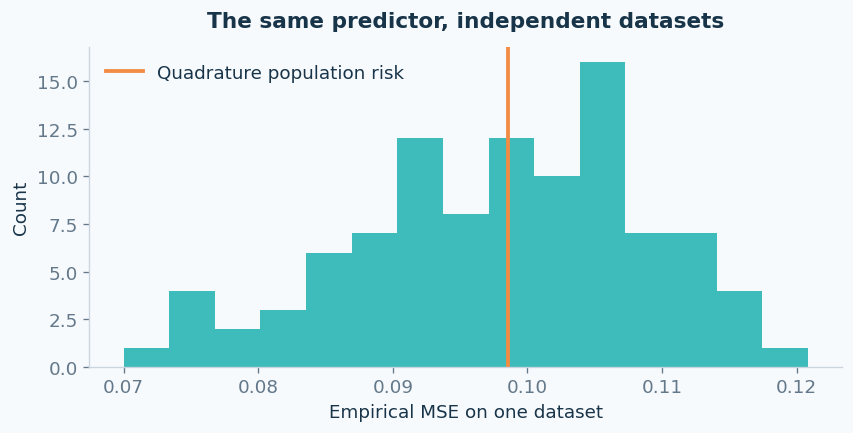

In [2]:
# EDIT: replace the baseline clean-risk estimate by your analytic expression.
N = 64
noise = .05
constant = .6
clean_risk_formula = 0.0          # baseline: assumes the constant predictor is exact
population_risk_formula = clean_risk_formula + noise**2
repeat_rng = np.random.default_rng(SEED)
empirical_risks = []
for repeat in range(100):
    x, y = sample_data(repeat_rng, N, noise)
    empirical_risks.append(np.mean((constant-y)**2))
empirical_risks = np.asarray(empirical_risks)
qx = (np.arange(20000)+.5)/20000
quadrature_risk = np.mean((constant-signal(qx))**2)+noise**2
print(f"Empirical mean ± dataset SD: {empirical_risks.mean():.6f} ± {empirical_risks.std(ddof=1):.6f}")
print(f"Your formula: {population_risk_formula:.6f}; quadrature diagnostic: {quadrature_risk:.6f}")
print("Formula feedback:", "matches" if abs(population_risk_formula-quadrature_risk) < 1e-6 else "revise clean-risk formula")
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.hist(empirical_risks, bins=15, alpha=.75)
ax.axvline(quadrature_risk, color=palette["orange"], label="Quadrature population risk")
ax.set(xlabel="Empirical MSE on one dataset", ylabel="Count", title="The same predictor, independent datasets")
ax.legend(); show_figure(fig)

**Your observations:** record the three sample sizes, their mean risks and their
standard deviations. State which quantity shrinks with sample size.

## B · Fit a baseline and diagnose model rigidity (L2-S10–L2-S14)

1. Extend `features` from the supplied affine basis to powers up to `degree` (or
   Legendre polynomials), maintaining one row per input and `degree + 1` columns.
2. Compare degrees 1, 2, 3 and 8 on the same train/validation split. Use `lstsq`,
   report the normal-equation residual and choose degree using validation MSE.
3. Repeat for 16 and 64 training observations. Does a larger model always win?
   Explain why explicitly inverting the normal equations is avoidable.

<details><summary>Hint</summary>

`np.polynomial.legendre.legvander(2*x[:, 0]-1, degree)` generates a scaled basis.
For a power basis use `np.vander(x[:, 0], N=degree+1, increasing=True)`.
</details>

In [3]:
# EDIT: implement the requested degree in features; the starter is always affine.
degree = 3
training_size = 64
train_x, train_y = sample_data(np.random.default_rng(SEED), training_size)
val_x, val_y = sample_data(np.random.default_rng(SEED+1), 128)
def features(x, degree):
    return np.column_stack([np.ones(len(x)), x[:, 0]])

A, V = features(train_x, degree), features(val_x, degree)
coefficient, *_ = np.linalg.lstsq(A, train_y[:, 0], rcond=None)
train_prediction, val_prediction = A @ coefficient, V @ coefficient
assert train_prediction.shape == (training_size,)
print("Basis feedback:", "requested column count" if A.shape[1] == degree+1 else "starter still uses two columns")
print(f"Train MSE {np.mean((train_prediction-train_y[:, 0])**2):.6f}")
print(f"Validation MSE {np.mean((val_prediction-val_y[:, 0])**2):.6f}")
print(f"Normal-equation residual {np.linalg.norm(A.T @ (train_prediction-train_y[:, 0])):.2e}")

Basis feedback: starter still uses two columns
Train MSE 0.079694
Validation MSE 0.125470
Normal-equation residual 2.71e-14


**Your comparison table:** degree, training size, training MSE, validation MSE,
normal-equation residual. Interpret a small residual with a large validation error.

## C · Build a network from hinges (L2-S15–L2-S35)

1. Replace the starter's single affine segment by the full piecewise linear interpolant,
   using ReLU hinges at the interior knots. Write the implied weights and biases.
2. Repeat with 4, 8, 16 and 32 intervals. Estimate the convergence rate of maximum grid
   error. Check interpolation at every knot, not just at the first one.
3. Change the target to $\sin(3\pi x)$ and then to $|x-0.37|$. Can a strategically placed
   knot represent the kink exactly? Compare uniform and nonuniform knots.
4. In your own words, distinguish the Cybenko/Pinkus density statement from guarantees
   about the necessary width, finite-data generalisation or an optimiser's convergence.

<details><summary>Hint</summary>

A slope change $s_i-s_{i-1}$ contributes $(s_i-s_{i-1})\max(0,x-t_i)$.
A linear combination of affine maps is still affine if all activations are identities.
Check the theorem's hypotheses before drawing conclusions about a chosen activation.
</details>

Knot interpolation error: 3.061e+00
Hinge feedback: add slope changes at interior knots
Maximum grid error: 3.06147


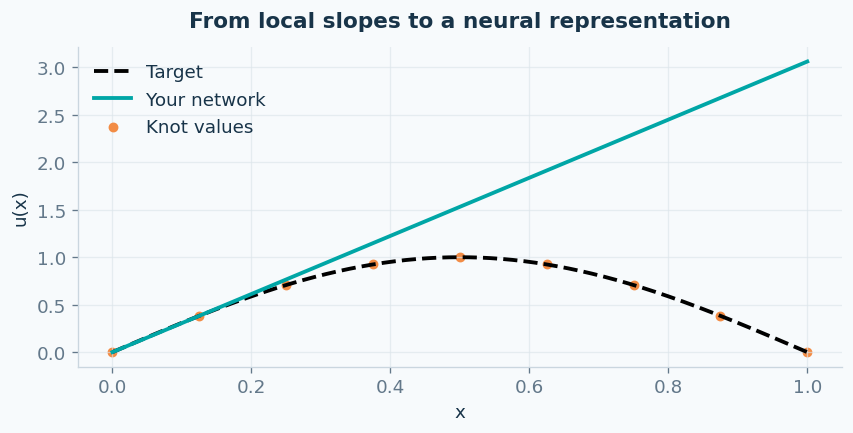

In [4]:
# EDIT: add the missing hinge contributions. The baseline extends the first segment.
intervals = 8
knots = np.linspace(0, 1, intervals+1)
def target(x):
    return np.sin(np.pi*x)
def hinge_predict(x, knots):
    values = target(knots)
    slopes = np.diff(values)/np.diff(knots)
    prediction = values[0] + slopes[0]*(np.asarray(x)-knots[0])
    return prediction

xgrid = np.linspace(0, 1, 1001)
prediction = hinge_predict(xgrid, knots)
knot_error = np.max(np.abs(hinge_predict(knots, knots)-target(knots)))
assert prediction.shape == xgrid.shape and np.isfinite(prediction).all()
print(f"Knot interpolation error: {knot_error:.3e}")
print("Hinge feedback:", "all knots matched" if knot_error < 1e-10 else "add slope changes at interior knots")
print(f"Maximum grid error: {np.max(np.abs(prediction-target(xgrid))):.5f}")
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.plot(xgrid, target(xgrid), "k--", label="Target")
ax.plot(xgrid, prediction, label="Your network")
ax.scatter(knots, target(knots), color=palette["orange"], s=24, label="Knot values")
ax.set(xlabel="x", ylabel="u(x)", title="From local slopes to a neural representation")
ax.legend(); ax.grid(); show_figure(fig)

**Your conclusions:** include the measured rate and one sentence identifying what
your construction knows about the signal that an ordinary supervised learner does not.

**Completion checklist:** risk formula agrees with quadrature; feature dimension changes
with degree; normal-equation residual is small; hinge construction matches all knots;
the discussion distinguishes representation from learning.

Continue with [practical 02](ML_Exercises_02_autograd_and_optimisation.ipynb).